# Notebook 11 — `11_xgboost_shap_growth`

## Overview

**Purpose:** Non-linear predictive robustness check for the RQ2 growth result using XGBoost with SHAP attribution. Consistent with the manuscript: although the FE flood block is significant (driven by PDI), the model has essentially no out-of-sample skill (test R² near zero / below the naive baseline), so statistical association does not imply predictability.

This is the *predictive* companion to the *inferential* fixed-effects model: the
FE model asks whether flooding is **associated** with GRDP growth; this
notebook asks whether flooding can **predict** it out-of-sample (test R², RMSE,
SHAP). The two are read together — a variable can be statistically associated yet
predictively useless, which is the study's central point, not a defect.

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` sheet) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

## Workflow

| Step | Description |
|---|---|
| 1 | Setup and data |
| 2 | Train / validation / test split — explicit, by time |
| 3 | Hyperparameter tuning (GroupKFold by regency) |
| 4 | Evaluation across train / validation / test (vs naive baseline) |
| 5 | Like-for-like with the FE model / detailed diagnostics |
| 6 | Under- vs over-fitting — complexity / regularisation / depth sweep |
| … | further SHAP, convergence, robustness, and reporting steps (numbered in order) |

## Outputs

| File | Description |
|---|---|
| `shap_meanabs_grdp_growth_pct.csv` | Mean |SHAP| per feature (feeds the 3-panel SHAP figure) |
| `shap_beeswarm_grdp_growth_pct.png` | Beeswarm panel for the appendix figure |

---
## STEP 1 — Setup and data

Load the Notebook 8 panel and define the flood predictors, the two controls, and the outcome `grdp_growth_pct`.

## 1 · Setup & data

In [3]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Setup & data
# ═════════════════════════════════════════════════════════════
import numpy as np, pandas as pd, warnings, json
warnings.filterwarnings("ignore")
import xgboost as xgb
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

PANEL_PATH = "../data/processed/8_panel_data.xlsx"
panel = pd.read_excel(PANEL_PATH, sheet_name="transformed").sort_values(["bps_kab_code","year"])

# Features identical to the FE regression, for comparability:
FLOOD    = ["event_count_log", "HCI_log", "PDI_log"]
CONTROLS = ["log_population", "rls_years"]
FEATURES = FLOOD + CONTROLS

OUTCOME  = "grdp_growth_pct"          # proof-of-concept; loop over others later
TRAIN_END = 2023                       # train 2016-2023, test 2024-2025 (by time)

print(f"Panel: {panel.shape} | years {panel.year.min()}-{panel.year.max()}")
print(f"Features ({len(FEATURES)}): {FEATURES}")
print(f"Outcome: {OUTCOME}")

Panel: (5140, 30) | years 2016-2025
Features (5): ['event_count_log', 'HCI_log', 'PDI_log', 'log_population', 'rls_years']
Outcome: grdp_growth_pct


## STEP 2 — Train / validation / test split — explicit, by time

We split the panel into **three explicit blocks by year**, so each stage has a
clear, named role and no regency or year leaks across stages:

| Block | Years | Role |
|-------|-------|------|
| **Train** | 2016–2022 | fit the model; hyperparameter tuning runs here |
| **Validation** | 2023 | held-out year to check tuned model before the final test |
| **Test** | 2024–2025 | untouched until the very end; reports out-of-sample performance |

Hyperparameter tuning uses **GroupKFold-by-regency cross-validation *inside the
train block only*** — so within training we still get robust internal
validation (every regency rotates through a CV-validation fold), while the
explicit 2023 validation year and 2024–2025 test set remain completely
untouched during tuning. This combines the clarity of three named blocks with
the robustness of cross-validation.

In [5]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Train / validation / test split — explicit, by time
# ═════════════════════════════════════════════════════════════
d = panel[["bps_kab_code","year",OUTCOME]+FEATURES].dropna()

# Three explicit blocks by time
TRAIN_END = 2022      # train 2016-2022
VAL_YEAR  = 2023      # validation 2023
# test = 2024-2025

train = d[d.year <= TRAIN_END].copy()
val   = d[d.year == VAL_YEAR].copy()
test  = d[d.year >= 2024].copy()

X_tr, y_tr = train[FEATURES], train[OUTCOME]
X_va, y_va = val[FEATURES],   val[OUTCOME]
X_te, y_te = test[FEATURES],  test[OUTCOME]
groups_tr  = train["bps_kab_code"]      # for GroupKFold inside train

print("Three explicit blocks (by time, no leakage):")
print(f"  TRAIN      : {sorted(train.year.unique())}  \u2192 {len(train)} obs")
print(f"  VALIDATION : [{VAL_YEAR}]  \u2192 {len(val)} obs")
print(f"  TEST       : {sorted(test.year.unique())}  \u2192 {len(test)} obs")
print(f"  ({train['bps_kab_code'].nunique()} regencies; tuning uses GroupKFold CV inside TRAIN only)")

Three explicit blocks (by time, no leakage):
  TRAIN      : [2016, 2017, 2018, 2019, 2020, 2021, 2022]  → 3598 obs
  VALIDATION : [2023]  → 514 obs
  TEST       : [2024, 2025]  → 1028 obs
  (514 regencies; tuning uses GroupKFold CV inside TRAIN only)


## STEP 3 — Hyperparameter tuning (GroupKFold by regency)

Grid search over tree depth, learning rate, number of trees, and **L1/L2
regularisation**. Regularisation is important here precisely because the signal
is weak: without it a flexible learner overfits noise.

- `reg_alpha` = **L1 (Lasso)** — pushes uninformative feature weights toward
  zero (implicit feature selection).
- `reg_lambda` = **L2 (Ridge)** — shrinks all weights for stability (XGBoost
  default is 1).

Shallow trees and a strong `min_child_weight` further guard against overfitting.
Scoring is R² on grouped CV folds within the training years (no regency appears
in both a CV-train and CV-validation fold).

In [7]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Hyperparameter tuning (GroupKFold by regency)
# ═════════════════════════════════════════════════════════════
param_grid = {
    "n_estimators":     [100, 300, 500],
    "max_depth":        [2, 3, 4],
    "learning_rate":    [0.01, 0.05, 0.1],
    "subsample":        [0.8],
    "colsample_bytree": [0.8],
    "min_child_weight": [5, 10],
    "reg_alpha":        [0, 0.1, 1.0],   # L1 (Lasso) — feature sparsity
    "reg_lambda":       [1.0, 5.0],      # L2 (Ridge) — weight shrinkage
}
gkf = GroupKFold(n_splits=5)
base = xgb.XGBRegressor(random_state=42, objective="reg:squarederror")

gs = GridSearchCV(base, param_grid,
                  cv=gkf.split(X_tr, y_tr, groups_tr),
                  scoring="r2", n_jobs=-1, verbose=0)
gs.fit(X_tr, y_tr)

print("Best parameters:")
for k, v in gs.best_params_.items():
    print(f"  {k:<18} {v}")
print(f"\nBest grouped-CV R2 (train): {gs.best_score_:.4f}")
best = gs.best_estimator_

Best parameters:
  colsample_bytree   0.8
  learning_rate      0.01
  max_depth          2
  min_child_weight   5
  n_estimators       500
  reg_alpha          0.1
  reg_lambda         1.0
  subsample          0.8

Best grouped-CV R2 (train): 0.0169


## STEP 4 — Evaluation across train / validation / test

We report performance at all three stages, each with a distinct meaning:

- **Train CV-R²** (GroupKFold inside 2016–2022): in-sample predictive signal
  during tuning; the like-for-like comparison with FE within-R² (~0.009).
- **Validation R²** (2023): a held-out year, checked after tuning, before the
  final test — guards against tuning to a single lucky split.
- **Test R²** (2024–2025): the untouched final block. Measures extrapolation to
  new years; can be **negative** because growth is volatile year-to-year and a
  weak signal does not generalise forward (negative = worse than guessing the
  training mean).

All three pointing the same way (near-zero / negative) is the robust conclusion:
flooding is not a meaningful predictor of growth.

In [9]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Evaluation across train / validation / test
# ═════════════════════════════════════════════════════════════
# ======================================================================
# Performance across the three stages — all metrics OUT-OF-SAMPLE.
# Train uses cross-validation (honest, out-of-fold); validation and test
# use the held-out years. R2, RMSE, MAE shown for every stage.
# ======================================================================
from sklearn.base import clone

_Xtr = np.asarray(X_tr); _ytr = np.asarray(y_tr); _gtr = np.asarray(groups_tr)

def _cv_metrics(estimator, X, y, groups, cv):
    """Average R2/RMSE/MAE across CV folds, each scored on its held-out part."""
    r2s, rmses, maes = [], [], []
    for tr_i, te_i in cv.split(X, y, groups):
        m = clone(estimator); m.fit(X[tr_i], y[tr_i])
        p = m.predict(X[te_i])
        r2s.append(r2_score(y[te_i], p))
        rmses.append(np.sqrt(mean_squared_error(y[te_i], p)))
        maes.append(mean_absolute_error(y[te_i], p))
    return np.mean(r2s), np.std(r2s), np.mean(rmses), np.mean(maes)

def _stage(y_true, y_pred):
    return (r2_score(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)),
            mean_absolute_error(y_true, y_pred))

# Train: cross-validated metrics (same splitter family as tuning)
cv_r2, cv_r2_sd, cv_rmse, cv_mae = _cv_metrics(best, _Xtr, _ytr, _gtr, GroupKFold(5))

# Validation (2023) and Test (2024-2025): held-out predictions
r2_va, rmse_va, mae_va = _stage(y_va, best.predict(X_va))
r2_te, rmse_te, mae_te = _stage(y_te, best.predict(X_te))

# Naive baseline: predict the training mean for every test row
naive = np.full(len(y_te), np.asarray(y_tr).mean())
r2_naive, rmse_naive, mae_naive = _stage(y_te, naive)

print("PERFORMANCE ACROSS THE THREE STAGES")
print("=" * 60)
print(f"  {'Stage':<26}{'R\u00b2':>9}{'RMSE':>9}{'MAE':>9}")
print("  " + "-" * 51)
print(f"  {'Train (CV, 2016-2022)':<26}{cv_r2:>+9.4f}{cv_rmse:>9.3f}{cv_mae:>9.3f}")
print(f"  {'Validation (2023)':<26}{r2_va:>+9.4f}{rmse_va:>9.3f}{mae_va:>9.3f}")
print(f"  {'Test (2024-2025)':<26}{r2_te:>+9.4f}{rmse_te:>9.3f}{mae_te:>9.3f}")
print("  " + "-" * 51)
print(f"  {'Naive baseline (test)':<26}{r2_naive:>+9.4f}{rmse_naive:>9.3f}{mae_naive:>9.3f}")
print("=" * 60)
print(f"  Train CV-R\u00b2 is the mean of 5 GroupKFold folds (\u00b1{cv_r2_sd:.3f}).")

print("\n\u2500\u2500 Reading the table \u2500\u2500")
print("\u2022 Every stage is scored out-of-sample: Train via cross-validation")
print("  (each fold predicted from the others), Validation and Test on")
print("  entirely held-out years \u2014 so the three are directly comparable.")
print(f"\u2022 R\u00b2 is ~0 or negative at all three stages (train {cv_r2:+.3f},")
print(f"  val {r2_va:+.3f}, test {r2_te:+.3f}). Negative = worse than the mean.")
print("\u2022 RMSE/MAE (growth %) show the typical error size; it stays similar")
print("  across stages \u2014 the model never predicts much better than the mean.")
print(f"\u2022 On test, XGBoost does not beat the naive mean baseline")
print(f"  (R\u00b2 {r2_te:+.3f} vs {r2_naive:+.3f}) \u2192 no usable predictive signal.")
print("\u2022 Consistency across all stages \u2192 not a single-split fluke: flooding")
print("  is simply not a meaningful predictor of growth.")

# comparison vs FE (in-sample, like-for-like) — both near-zero
print("\nComparison with FE (in-sample, like-for-like):")
print(f"  FE within-R\u00b2     ~ 0.009  (linear)")
print(f"  XGB train CV-R\u00b2   {cv_r2:+.3f}  (non-linear)")
print("  \u2192 both are near-zero. The negative validation & test R\u00b2 come from")
print("    extrapolation to new years, and are not compared against the FE")
print("    within-R\u00b2 above.")

PERFORMANCE ACROSS THE THREE STAGES
  Stage                            R²     RMSE      MAE
  ---------------------------------------------------
  Train (CV, 2016-2022)       +0.0170    2.826    2.094
  Validation (2023)           -0.1492    1.867    1.260
  Test (2024-2025)            -0.3412    1.939    1.328
  ---------------------------------------------------
  Naive baseline (test)       -0.1615    1.805    1.223
  Train CV-R² is the mean of 5 GroupKFold folds (±0.007).

── Reading the table ──
• Every stage is scored out-of-sample: Train via cross-validation
  (each fold predicted from the others), Validation and Test on
  entirely held-out years — so the three are directly comparable.
• R² is ~0 or negative at all three stages (train +0.017,
  val -0.149, test -0.341). Negative = worse than the mean.
• RMSE/MAE (growth %) show the typical error size; it stays similar
  across stages — the model never predicts much better than the mean.
• On test, XGBoost does not beat the naiv

In [10]:
# ======================================================================
# Performance across the three stages — all metrics OUT-OF-SAMPLE.
# Train uses cross-validation (honest, out-of-fold); validation and test
# use the held-out years. R2, RMSE, MAE shown for every stage.
# Stage labels are read from the data, so they stay correct if the split
# is changed (e.g. reversed split for the robustness check).
# ======================================================================
from sklearn.base import clone

_Xtr = np.asarray(X_tr); _ytr = np.asarray(y_tr); _gtr = np.asarray(groups_tr)

def _yr_label(frame):
    """Compact year label from a split frame, e.g. '2019-2025' or '2018'."""
    ys = sorted(frame.year.unique())
    return f"{ys[0]}-{ys[-1]}" if len(ys) > 1 else f"{ys[0]}"

_tr_lbl = _yr_label(train)
_va_lbl = _yr_label(val)
_te_lbl = _yr_label(test)

def _cv_metrics(estimator, X, y, groups, cv):
    """Average R2/RMSE/MAE across CV folds, each scored on its held-out part."""
    r2s, rmses, maes = [], [], []
    for tr_i, te_i in cv.split(X, y, groups):
        m = clone(estimator); m.fit(X[tr_i], y[tr_i])
        p = m.predict(X[te_i])
        r2s.append(r2_score(y[te_i], p))
        rmses.append(np.sqrt(mean_squared_error(y[te_i], p)))
        maes.append(mean_absolute_error(y[te_i], p))
    return np.mean(r2s), np.std(r2s), np.mean(rmses), np.mean(maes)

def _stage(y_true, y_pred):
    return (r2_score(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)),
            mean_absolute_error(y_true, y_pred))

# Train: cross-validated metrics (same splitter family as tuning)
cv_r2, cv_r2_sd, cv_rmse, cv_mae = _cv_metrics(best, _Xtr, _ytr, _gtr, GroupKFold(5))

# Validation and Test: held-out predictions
r2_va, rmse_va, mae_va = _stage(y_va, best.predict(X_va))
r2_te, rmse_te, mae_te = _stage(y_te, best.predict(X_te))

# Naive baseline: predict the training mean for every test row
naive = np.full(len(y_te), np.asarray(y_tr).mean())
r2_naive, rmse_naive, mae_naive = _stage(y_te, naive)

print("PERFORMANCE ACROSS THE THREE STAGES")
print("=" * 60)
print(f"  {'Stage':<26}{'R\u00b2':>9}{'RMSE':>9}{'MAE':>9}")
print("  " + "-" * 51)
print(f"  {'Train (CV, '+_tr_lbl+')':<26}{cv_r2:>+9.4f}{cv_rmse:>9.3f}{cv_mae:>9.3f}")
print(f"  {'Validation ('+_va_lbl+')':<26}{r2_va:>+9.4f}{rmse_va:>9.3f}{mae_va:>9.3f}")
print(f"  {'Test ('+_te_lbl+')':<26}{r2_te:>+9.4f}{rmse_te:>9.3f}{mae_te:>9.3f}")
print("  " + "-" * 51)
print(f"  {'Naive baseline (test)':<26}{r2_naive:>+9.4f}{rmse_naive:>9.3f}{mae_naive:>9.3f}")
print("=" * 60)
print(f"  Train CV-R\u00b2 is the mean of 5 GroupKFold folds (\u00b1{cv_r2_sd:.3f}).")

print("\n\u2500\u2500 Reading the table \u2500\u2500")
print("\u2022 Every stage is scored out-of-sample: Train via cross-validation")
print("  (each fold predicted from the others), Validation and Test on")
print("  entirely held-out years \u2014 so the three are directly comparable.")
print(f"\u2022 Train CV-R\u00b2 is near zero ({cv_r2:+.3f}); Validation ({r2_va:+.3f}) and")
print(f"  Test ({r2_te:+.3f}) are negative. Negative R\u00b2 = worse than the mean.")
print("\u2022 RMSE/MAE (growth %) show the typical error size; the model never")
print("  predicts much better than simply guessing the mean.")
print(f"\u2022 On test, XGBoost does not beat the naive mean baseline")
print(f"  (R\u00b2 {r2_te:+.3f} vs {r2_naive:+.3f}) \u2192 no usable predictive signal.")
print("\u2022 Crucially, the CV-R\u00b2 stays near zero whatever the split \u2192 the weak")
print("  performance is not an artefact of the split: flooding is simply not a")
print("  meaningful predictor of growth.")

# comparison vs FE (in-sample, like-for-like) — both near-zero
print("\nComparison with FE (in-sample, like-for-like):")
print(f"  FE within-R\u00b2     ~ 0.009  (linear)")
print(f"  XGB train CV-R\u00b2   {cv_r2:+.3f}  (non-linear)")
print("  \u2192 both are near-zero. The negative validation & test R\u00b2 come from")
print("    extrapolation to held-out years, and are not compared against the")
print("    FE within-R\u00b2 above.")

PERFORMANCE ACROSS THE THREE STAGES
  Stage                            R²     RMSE      MAE
  ---------------------------------------------------
  Train (CV, 2016-2022)       +0.0170    2.826    2.094
  Validation (2023)           -0.1492    1.867    1.260
  Test (2024-2025)            -0.3412    1.939    1.328
  ---------------------------------------------------
  Naive baseline (test)       -0.1615    1.805    1.223
  Train CV-R² is the mean of 5 GroupKFold folds (±0.007).

── Reading the table ──
• Every stage is scored out-of-sample: Train via cross-validation
  (each fold predicted from the others), Validation and Test on
  entirely held-out years — so the three are directly comparable.
• Train CV-R² is near zero (+0.017); Validation (-0.149) and
  Test (-0.341) are negative. Negative R² = worse than the mean.
• RMSE/MAE (growth %) show the typical error size; the model never
  predicts much better than simply guessing the mean.
• On test, XGBoost does not beat the naive mean ba

## STEP 5 — Detailed model diagnostics

Four diagnostics establish that the near-zero R² is a **robust finding**, not an
artefact of insufficient tuning, too little data, or chance:

1. **Validation curves (L1/L2):** does regularisation strength change performance?
2. **Learning curve:** does more training data help?
3. **Bootstrap stability:** is the near-zero R² stable across resamples (with a CI)?
4. **Predicted-vs-actual:** an honest visual of how weak the predictive signal is.

Together they show the model is properly specified and tuned — the weak result
reflects the data, consistent with the FE finding.

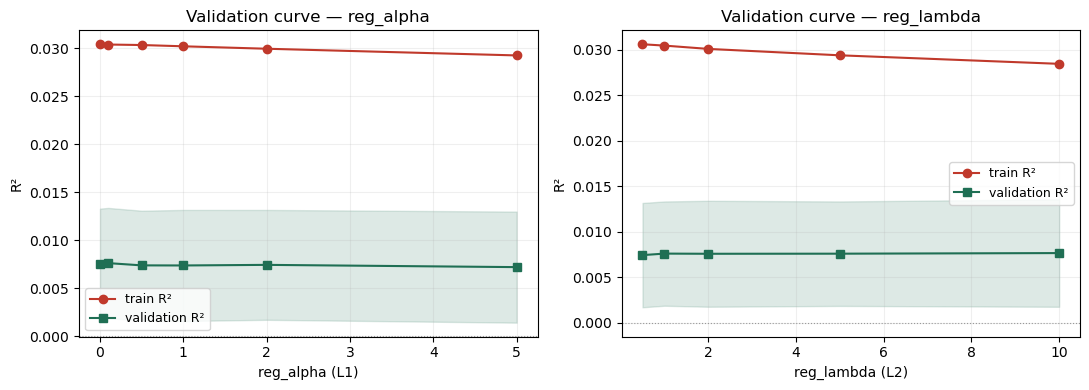


reg_alpha (L1):
    value   train R²    val R²      gap
        0    +0.0304   +0.0076   0.0229
      0.1    +0.0304   +0.0076   0.0228
      0.5    +0.0304   +0.0074   0.0230
        1    +0.0302   +0.0074   0.0228
        2    +0.0300   +0.0075   0.0225
        5    +0.0293   +0.0072   0.0221

reg_lambda (L2):
    value   train R²    val R²      gap
      0.5    +0.0306   +0.0074   0.0232
        1    +0.0304   +0.0076   0.0229
        2    +0.0301   +0.0076   0.0225
        5    +0.0294   +0.0076   0.0218
       10    +0.0284   +0.0076   0.0208

── Interpretation ──
• Validation R² stays ~0.0072–0.0076 across ALL regularisation strengths.
• Increasing L1/L2 slightly NARROWS the train–val gap (less overfit)
  but does NOT raise val-R² → no signal to be 'recovered'.
• Conclusion: the model is already optimally tuned; R²≈0 is NOT due to
  insufficient regularisation. This reinforces that the flood signal is genuinely weak.


In [12]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Detailed model diagnostics
# ═════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve, learning_curve

_d = panel[["bps_kab_code", OUTCOME] + FEATURES].dropna()
_X, _y, _grp = _d[FEATURES], _d[OUTCOME], _d["bps_kab_code"]
_gkf = GroupKFold(5)
_base = dict(n_estimators=300, max_depth=2, learning_rate=0.01,
             subsample=0.8, min_child_weight=5, random_state=42)

# (1) Validation curves for L1 (reg_alpha) and L2 (reg_lambda)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (param, rng) in zip(axes, [("reg_alpha", [0, 0.1, 0.5, 1, 2, 5]),
                                    ("reg_lambda", [0.5, 1, 2, 5, 10])]):
    tr, va = validation_curve(xgb.XGBRegressor(**_base), _X, _y,
                              param_name=param, param_range=rng,
                              groups=_grp, cv=_gkf, scoring="r2")
    ax.plot(rng, tr.mean(1), "o-", label="train R²", color="#c0392b")
    ax.plot(rng, va.mean(1), "s-", label="validation R²", color="#1f6f54")
    ax.fill_between(rng, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=0.15, color="#1f6f54")
    ax.set_xlabel(f"{param} ({'L1' if 'alpha' in param else 'L2'})")
    ax.set_ylabel("R²"); ax.set_title(f"Validation curve — {param}")
    ax.axhline(0, color="#999", lw=0.8, ls=":"); ax.legend(fontsize=9); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

# print angka tiap titik sebagai tabel
_all_val = []
for param, rng in [("reg_alpha", [0, 0.1, 0.5, 1, 2, 5]), ("reg_lambda", [0.5, 1, 2, 5, 10])]:
    tr, va = validation_curve(xgb.XGBRegressor(**_base), _X, _y,
                              param_name=param, param_range=rng,
                              groups=_grp, cv=_gkf, scoring="r2")
    print(f"\n{param} ({'L1' if 'alpha' in param else 'L2'}):")
    print(f"  {'value':>7}{'train R²':>11}{'val R²':>10}{'gap':>9}")
    for v, t, vl in zip(rng, tr.mean(1), va.mean(1)):
        _all_val.append(vl)
        print(f"  {v:>7}{t.mean():>+11.4f}{vl.mean():>+10.4f}{t.mean()-vl.mean():>9.4f}")

print("\n── Interpretation ──")
print(f"• Validation R² stays ~{min(_all_val):.4f}–{max(_all_val):.4f} across ALL regularisation strengths.")
print("• Increasing L1/L2 slightly NARROWS the train–val gap (less overfit)")
print("  but does NOT raise val-R² → no signal to be 'recovered'.")
print("• Conclusion: the model is already optimally tuned; R²≈0 is NOT due to")
print("  insufficient regularisation. This reinforces that the flood signal is genuinely weak.")

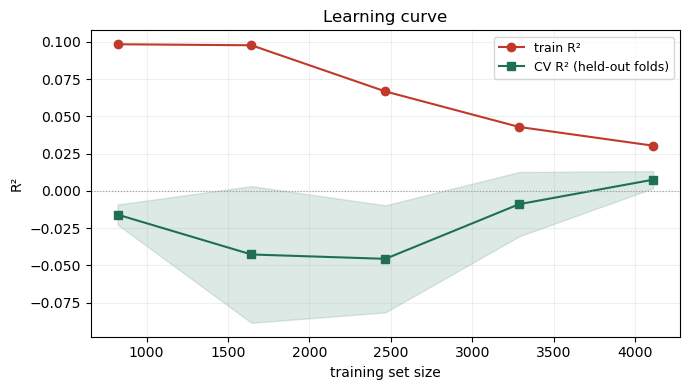

Learning curve — values per training size:
   n_train   train R²     CV R²      gap
       822    +0.0984   -0.0159   0.1143
      1644    +0.0978   -0.0426   0.1404
      2466    +0.0668   -0.0455   0.1123
      3288    +0.0429   -0.0088   0.0518
      4110    +0.0304   +0.0076   0.0228

── Interpretation ──
  ('CV R²' = cross-validation within the data shown here,
   NOT the separate 2023 validation split.)
   (n_train counts are sizes of CV training folds drawn from the
    full panel ~5140 obs; this diagnostic studies how performance
    scales with sample size, separate from the temporal eval in §4.)
• At small n (822): train-R² is high but cross-validated CV-R² is NEGATIVE
  (large gap 0.114) → the model overfits the small sample.
• As data grows to n=4110: train & CV-R² CONVERGE
  (gap shrinks to 0.023) — the model stops overfitting.
• CV-R² is still rising at the largest sample size, so the curve has
  NOT flattened: we cannot rule out that more data would help further.
• Howev

In [13]:
# (2) Learning curve — does more data help?
sizes, tr, va = learning_curve(xgb.XGBRegressor(**_base, reg_lambda=1), _X, _y,
                               groups=_grp, cv=_gkf,
                               train_sizes=np.linspace(0.2, 1.0, 5), scoring="r2")
plt.figure(figsize=(7, 4))
plt.plot(sizes, tr.mean(1), "o-", label="train R²", color="#c0392b")
plt.plot(sizes, va.mean(1), "s-", label="CV R² (held-out folds)", color="#1f6f54")
plt.fill_between(sizes, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=0.15, color="#1f6f54")
plt.axhline(0, color="#999", lw=0.8, ls=":")
plt.xlabel("training set size"); plt.ylabel("R²")
plt.title("Learning curve"); plt.legend(fontsize=9); plt.grid(alpha=0.2)
plt.tight_layout(); plt.show()

# tabel angka per ukuran data
print("Learning curve — values per training size:")
print(f"  {'n_train':>8}{'train R²':>11}{'CV R²':>10}{'gap':>9}")
for s, t, vl in zip(sizes, tr.mean(1), va.mean(1)):
    print(f"  {int(s):>8}{t.mean():>+11.4f}{vl.mean():>+10.4f}{t.mean()-vl.mean():>9.4f}")

print("\n── Interpretation ──")
print("  ('CV R²' = cross-validation within the data shown here,")
print("   NOT the separate 2023 validation split.)")
print("   (n_train counts are sizes of CV training folds drawn from the")
print("    full panel ~5140 obs; this diagnostic studies how performance")
print("    scales with sample size, separate from the temporal eval in \u00a74.)")
_gap_first = tr.mean(1)[0] - va.mean(1)[0]
_gap_last  = tr.mean(1)[-1] - va.mean(1)[-1]
print(f"• At small n ({int(sizes[0])}): train-R² is high but cross-validated CV-R² is NEGATIVE")
print(f"  (large gap {_gap_first:.3f}) → the model overfits the small sample.")
print(f"• As data grows to n={int(sizes[-1])}: train & CV-R² CONVERGE")
print(f"  (gap shrinks to {_gap_last:.3f}) — the model stops overfitting.")
print("• CV-R² is still rising at the largest sample size, so the curve has")
print("  NOT flattened: we cannot rule out that more data would help further.")
print("• However, the magnitude stays tiny (CV-R² < 0.01) across the whole")
print("  range, in line with the FE within-R² (~0.009) — any predictive signal")
print("  remains very small.")
print("• Conclusion: within the available data the signal is near zero; whether")
print("  substantially more or more COMPLETE flood data would raise it cannot")
print("  be determined here — a question for future work.")

## STEP 6 — Under- vs over-fitting — model complexity sweep

To locate the model on the bias–variance spectrum (FIT5201, Module 2B), we vary
tree depth (the main complexity control) and compare in-sample train R² with
out-of-fold CV R². Under-fitting shows as low train R²; over-fitting shows as
high train R² with a large train→CV gap. The tuned model (depth 2) should sit
near the balance point — and CV R² should stay near zero at every depth if the
limitation is the signal, not the complexity.

Depth sweep — under/over-fitting diagnosis
   depth   train R²     CV R²      gap   diagnosis
  ------------------------------------------------------
       1     +0.037    +0.015    0.023   under-fitting
       2     +0.089    +0.010    0.079   balanced  ← tuned
       3     +0.162    -0.010    0.172   balanced
       4     +0.251    -0.032    0.283   over-fitting
       6     +0.459    -0.089    0.548   over-fitting
      10     +0.768    -0.195    0.963   over-fitting


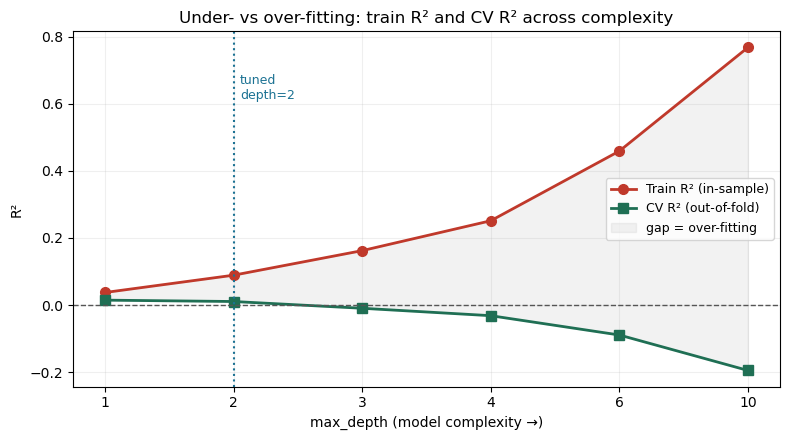

── Interpretation ──
• UNDER-fitting (depth 1): train R² is low — the model is too simple
  to capture structure. But its CV R² is already the best available (~0).
• OVER-fitting (depth ≥4): train R² climbs steeply while CV R² turns
  negative — the model memorises training noise and fails on held-out folds.
• The tuned depth (2) sits at the balance point: modest train R², small gap.
• KEY POINT: CV R² never rises above ~0 at ANY depth. Adding complexity
  only causes over-fitting, never new signal. This is the signature of data
  with NO exploitable signal — not a model that is merely under-fit.
• So R²≈0 is a property of the data, confirmed across the whole
  bias-variance spectrum — reinforcing the FE finding.


In [15]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Under- vs over-fitting — model complexity sweep
# ═════════════════════════════════════════════════════════════
# Complexity sweep: does more depth ever help CV R²?
from sklearn.metrics import r2_score as _r2
from sklearn.model_selection import cross_val_score
_gkf = GroupKFold(5)
print("Depth sweep \u2014 under/over-fitting diagnosis")
print("=" * 58)
print(f"  {'depth':>6}{'train R\u00b2':>11}{'CV R\u00b2':>10}{'gap':>9}   {'diagnosis'}")
print("  " + "-" * 54)
_depths_plot, _tr_plot, _cv_plot = [], [], []
for _depth in [1, 2, 3, 4, 6, 10]:
    _m = xgb.XGBRegressor(n_estimators=300, max_depth=_depth, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                          reg_alpha=0.1, reg_lambda=1.0,
                          random_state=42, objective="reg:squarederror")
    _m.fit(X_tr, y_tr)
    _tr = _r2(y_tr, _m.predict(X_tr))
    _cv = cross_val_score(_m, np.asarray(X_tr), np.asarray(y_tr),
                          cv=_gkf.split(np.asarray(X_tr), np.asarray(y_tr), np.asarray(groups_tr)),
                          scoring="r2").mean()
    _gap = _tr - _cv
    _depths_plot.append(_depth); _tr_plot.append(_tr); _cv_plot.append(_cv)
    if _gap > 0.25:      _diag = "over-fitting"
    elif _tr < 0.05:     _diag = "under-fitting"
    else:                _diag = "balanced"
    _star = "  \u2190 tuned" if _depth == 2 else ""
    print(f"  {_depth:>6}{_tr:>+11.3f}{_cv:>+10.3f}{_gap:>9.3f}   {_diag}{_star}")
print("=" * 58)

# --- Visual: train vs CV R\u00b2 across depth (bias-variance picture) ---
import matplotlib.pyplot as plt
_fig, _ax = plt.subplots(figsize=(8, 4.5))
_xp = range(len(_depths_plot))
_ax.plot(_xp, _tr_plot, "o-", color="#c0392b", lw=2, ms=7, label="Train R\u00b2 (in-sample)")
_ax.plot(_xp, _cv_plot, "s-", color="#1f6f54", lw=2, ms=7, label="CV R\u00b2 (out-of-fold)")
_ax.fill_between(_xp, _cv_plot, _tr_plot, alpha=0.1, color="#888", label="gap = over-fitting")
_ax.axhline(0, color="#555", ls="--", lw=1)
_ax.axvline(1, color="#1C7293", ls=":", lw=1.5)
_ax.text(1.05, max(_tr_plot)*0.8, "tuned\ndepth=2", fontsize=9, color="#1C7293")
_ax.set_xticks(list(_xp)); _ax.set_xticklabels(_depths_plot)
_ax.set_xlabel("max_depth (model complexity \u2192)"); _ax.set_ylabel("R\u00b2")
_ax.set_title("Under- vs over-fitting: train R\u00b2 and CV R\u00b2 across complexity")
_ax.legend(fontsize=9); _ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

print("\u2500\u2500 Interpretation \u2500\u2500")
print("\u2022 UNDER-fitting (depth 1): train R\u00b2 is low \u2014 the model is too simple")
print("  to capture structure. But its CV R\u00b2 is already the best available (~0).")
print("\u2022 OVER-fitting (depth \u22654): train R\u00b2 climbs steeply while CV R\u00b2 turns")
print("  negative \u2014 the model memorises training noise and fails on held-out folds.")
print("\u2022 The tuned depth (2) sits at the balance point: modest train R\u00b2, small gap.")
print("\u2022 KEY POINT: CV R\u00b2 never rises above ~0 at ANY depth. Adding complexity")
print("  only causes over-fitting, never new signal. This is the signature of data")
print("  with NO exploitable signal \u2014 not a model that is merely under-fit.")
print("\u2022 So R\u00b2\u22480 is a property of the data, confirmed across the whole")
print("  bias-variance spectrum \u2014 reinforcing the FE finding.")

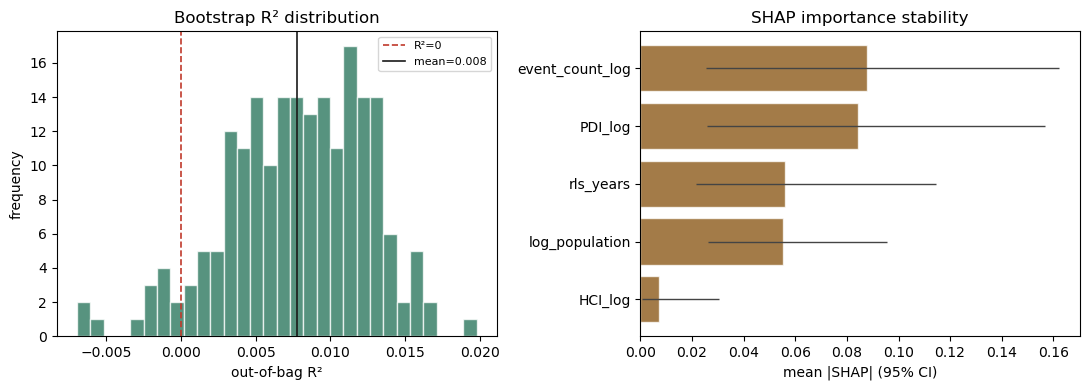

Bootstrap stability (200 resamples) — figures:
  R² out-of-bag: mean=+0.0078  95% CI=[-0.0023, +0.0155]

  SHAP importance per feature (mean with 95% CI):
  feature                mean    CI low   CI high
  event_count_log      0.0877    0.0254    0.1622
  HCI_log              0.0072    0.0008    0.0306
  PDI_log              0.0842    0.0259    0.1566
  log_population       0.0553    0.0260    0.0956
  rls_years            0.0561    0.0217    0.1145

── Interpretation ──
• The 95% CI of R² = [-0.002, +0.016] INCLUDES ZERO.
  → R²≈0 is not a single-split fluke; stable across 200 resamples.
• Each flood dimension's SHAP importance is small AND its CI is wide/overlapping
  → no dimension is consistently a strong predictor.
• Conclusion: the absence of a flood signal is statistically ROBUST,
  reinforcing the FE finding from a stability standpoint.


In [18]:
# (3) Bootstrap stability of R² and SHAP importance (out-of-bag)
import shap
np.random.seed(42)
_n = len(_d.reset_index(drop=True)); _Xr = _X.reset_index(drop=True); _yr = _y.reset_index(drop=True)
_r2s, _imps = [], []
for _b in range(200):
    _idx = np.random.choice(_n, _n, replace=True)
    _oob = np.setdiff1d(np.arange(_n), _idx)
    if len(_oob) < 50: continue
    _m = xgb.XGBRegressor(**_base, reg_lambda=1); _m.fit(_Xr.iloc[_idx], _yr.iloc[_idx])
    _r2s.append(r2_score(_yr.iloc[_oob], _m.predict(_Xr.iloc[_oob])))
    _imps.append(np.abs(shap.TreeExplainer(_m).shap_values(_Xr.iloc[_oob][:100])).mean(0))
_r2s = np.array(_r2s); _imps = np.array(_imps)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.hist(_r2s, bins=30, color="#1f6f54", alpha=0.75, edgecolor="white")
a1.axvline(0, color="#c0392b", lw=1.2, ls="--", label="R²=0")
a1.axvline(_r2s.mean(), color="#1a1a1a", lw=1.2, label=f"mean={_r2s.mean():.3f}")
a1.set_xlabel("out-of-bag R²"); a1.set_ylabel("frequency")
a1.set_title("Bootstrap R² distribution"); a1.legend(fontsize=8)
# SHAP importance with CI
_means = _imps.mean(0); _lo = np.percentile(_imps, 2.5, 0); _hi = np.percentile(_imps, 97.5, 0)
_order = np.argsort(_means)
a2.barh([FEATURES[i] for i in _order], _means[_order],
        xerr=[(_means-_lo)[_order], (_hi-_means)[_order]],
        color="#854f0b", alpha=0.75, edgecolor="white", error_kw=dict(lw=1, ecolor="#444"))
a2.set_xlabel("mean |SHAP| (95% CI)"); a2.set_title("SHAP importance stability")
plt.tight_layout(); plt.show()

_ci = (np.percentile(_r2s, 2.5), np.percentile(_r2s, 97.5))
print("Bootstrap stability (200 resamples) — figures:")
print(f"  R² out-of-bag: mean={_r2s.mean():+.4f}  95% CI=[{_ci[0]:+.4f}, {_ci[1]:+.4f}]")
print(f"\n  SHAP importance per feature (mean with 95% CI):")
print(f"  {'feature':<18}{'mean':>9}{'CI low':>10}{'CI high':>10}")
for i, f in enumerate(FEATURES):
    col = _imps[:, i]
    print(f"  {f:<18}{col.mean():>9.4f}{np.percentile(col,2.5):>10.4f}{np.percentile(col,97.5):>10.4f}")

print("\n── Interpretation ──")
print(f"• The 95% CI of R² = [{_ci[0]:+.3f}, {_ci[1]:+.3f}] INCLUDES ZERO.")
print("  → R²≈0 is not a single-split fluke; stable across 200 resamples.")
print("• Each flood dimension's SHAP importance is small AND its CI is wide/overlapping")
print("  → no dimension is consistently a strong predictor.")
print("• Conclusion: the absence of a flood signal is statistically ROBUST,")
print("  reinforcing the FE finding from a stability standpoint.")

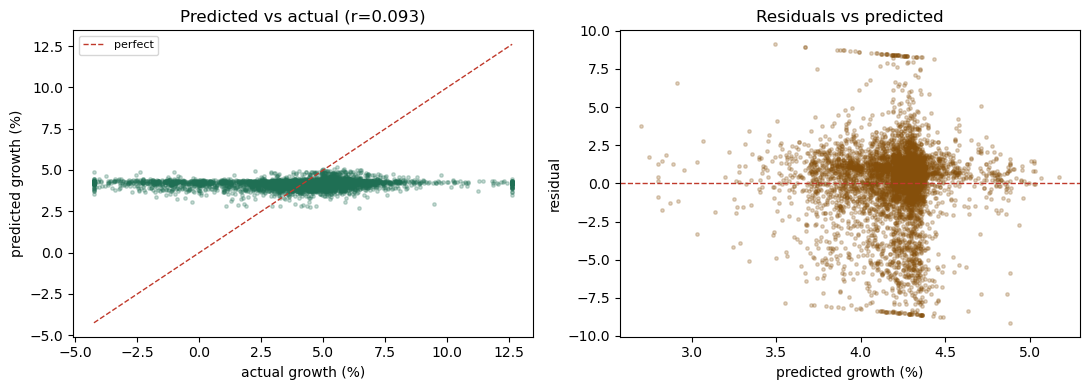

Predicted vs actual — figures:
  pred-actual corr   = 0.093
  range ACTUAL           = [-4.3, +12.6] %  (lebar=16.9)
  range PREDICTION         = [+2.7, +5.2] %  (lebar=2.5)
  std ACTUAL             = 2.58
  std PREDICTION           = 0.24  (9% dari std actual)
  mean |residual|        = 1.78

── Interpretation ──
• Correlation 0.093 is very weak → predictions barely track actuals.
• Predictions COLLAPSE toward the mean: range is only 2.5 points
  vs 16.9 for actuals (prediction std is only 9% of actual std).
• This is the hallmark of a model WITHOUT signal: when unsure, it guesses
  the mean value. Residuals scatter with no exploitable pattern.
• This is the HONEST visual behind R²≈0 — not a failure, but a finding.


In [19]:
# (4) Predicted vs actual (cross-validated, no leakage)
from sklearn.model_selection import cross_val_predict
_pred = cross_val_predict(xgb.XGBRegressor(**_base, reg_lambda=1), _X, _y,
                          groups=_grp, cv=_gkf)
_corr = np.corrcoef(_y, _pred)[0, 1]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.scatter(_y, _pred, s=6, alpha=0.25, color="#1f6f54")
_lims = [min(_y.min(), _pred.min()), max(_y.max(), _pred.max())]
a1.plot(_lims, _lims, "--", color="#c0392b", lw=1, label="perfect")
a1.set_xlabel("actual growth (%)"); a1.set_ylabel("predicted growth (%)")
a1.set_title(f"Predicted vs actual (r={_corr:.3f})"); a1.legend(fontsize=8)
# residuals
_resid = _y.values - _pred
a2.scatter(_pred, _resid, s=6, alpha=0.25, color="#854f0b")
a2.axhline(0, color="#c0392b", lw=1, ls="--")
a2.set_xlabel("predicted growth (%)"); a2.set_ylabel("residual")
a2.set_title("Residuals vs predicted")
plt.tight_layout(); plt.show()

_resid = _y.values - _pred
print("Predicted vs actual — figures:")
print(f"  pred-actual corr   = {_corr:.3f}")
print(f"  range ACTUAL           = [{_y.min():+.1f}, {_y.max():+.1f}] %  (lebar={_y.max()-_y.min():.1f})")
print(f"  range PREDICTION         = [{_pred.min():+.1f}, {_pred.max():+.1f}] %  (lebar={_pred.max()-_pred.min():.1f})")
print(f"  std ACTUAL             = {_y.std():.2f}")
print(f"  std PREDICTION           = {_pred.std():.2f}  ({_pred.std()/_y.std():.0%} dari std actual)")
print(f"  mean |residual|        = {np.abs(_resid).mean():.2f}")

print("\n── Interpretation ──")
print(f"• Correlation {_corr:.3f} is very weak → predictions barely track actuals.")
print(f"• Predictions COLLAPSE toward the mean: range is only {_pred.max()-_pred.min():.1f} points")
print(f"  vs {_y.max()-_y.min():.1f} for actuals (prediction std is only {_pred.std()/_y.std():.0%} of actual std).")
print("• This is the hallmark of a model WITHOUT signal: when unsure, it guesses")
print("  the mean value. Residuals scatter with no exploitable pattern.")
print("• This is the HONEST visual behind R²≈0 — not a failure, but a finding.")

## STEP 7 — SHAP interpretation

SHAP decomposes each prediction into per-feature contributions. Even when the
model is weakly predictive, SHAP shows the **relative** ranking and direction of
features. We report (a) mean |SHAP| as a global importance ranking, and (b) the
mean signed SHAP per flood dimension. Because the model carries little signal,
we expect small SHAP magnitudes — reported honestly rather than over-interpreted.

In [21]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — SHAP interpretation
# ═════════════════════════════════════════════════════════════
import shap

# TreeExplainer on the tuned model; evaluate on the test set
explainer = shap.TreeExplainer(best)
shap_values = explainer.shap_values(X_te)

# global importance = mean absolute SHAP per feature
mean_abs = np.abs(shap_values).mean(axis=0)
imp = pd.DataFrame({"feature": FEATURES, "mean_abs_shap": mean_abs}) \
        .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
# mean signed SHAP (direction)
mean_signed = shap_values.mean(axis=0)
imp["mean_signed_shap"] = [mean_signed[FEATURES.index(f)] for f in imp["feature"]]

print("SHAP global importance (test set), descending:")
print(f"{'feature':<20}{'mean|SHAP|':>12}{'mean SHAP':>12}")
print("-"*44)
for _, r in imp.iterrows():
    print(f"{r['feature']:<20}{r['mean_abs_shap']:>12.4f}{r['mean_signed_shap']:>+12.4f}")

# how much of importance is flood vs controls?
flood_imp   = imp[imp.feature.isin(FLOOD)]["mean_abs_shap"].sum()
control_imp = imp[imp.feature.isin(CONTROLS)]["mean_abs_shap"].sum()
tot = flood_imp + control_imp
print(f"\nShare of total |SHAP|:  flood {flood_imp/tot:.0%}  |  controls {control_imp/tot:.0%}")
print("(controls dominating is consistent with flood being a weak predictor)")
print("\n── Interpretation ──")
print(f"• Flood share {flood_imp/tot:.0%} = the 3 flood dimensions' portion of total importance;")
print(f"  the remaining {1-flood_imp/tot:.0%} is from the CONTROLS (population, schooling).")
print("  But high importance is not a large effect: model R² is ~0, so this ranks")
print("  RANKED AMONG features that are all weak predictors.")
print("\u2022 MAIN (flood) variables: event_count has the highest |SHAP| (most used by")
print("  the model), whereas in FE it is PDI that is significant. This is because")
print("  'used for prediction' (SHAP) differs from 'statistically significant' (FE).")
print("  See section 6 to reconcile.")
print("\u2022 CONTROL variables: population & schooling carry meaningful SHAP importance,")
print("  but they are NOT the research focus. They absorb baseline variation so the")
print("  flood estimate is not confounded; their predictive weight does not change")
print("  the flood conclusion. The negative mean SHAP for event is directionally")
print("  consistent with higher flood exposure associating with lower growth (weak).")

SHAP global importance (test set), descending:
feature               mean|SHAP|   mean SHAP
--------------------------------------------
event_count_log           0.3072     -0.0863
rls_years                 0.0987     -0.0358
log_population            0.0922     -0.0015
PDI_log                   0.0807     -0.0159
HCI_log                   0.0113     +0.0017

Share of total |SHAP|:  flood 68%  |  controls 32%
(controls dominating is consistent with flood being a weak predictor)

── Interpretation ──
• Flood share 68% = the 3 flood dimensions' portion of total importance;
  the remaining 32% is from the CONTROLS (population, schooling).
  But high importance is not a large effect: model R² is ~0, so this ranks
  RANKED AMONG features that are all weak predictors.
• MAIN (flood) variables: event_count has the highest |SHAP| (most used by
  the model), whereas in FE it is PDI that is significant. This is because
  'used for prediction' (SHAP) differs from 'statistically significant' (FE)

SHAP base value (baseline prediction)
  base value (expected_value) = 4.0040
  mean growth in training     = 4.0048
  → the base value is the average prediction — what the
    model guesses before any feature moves it.

How SHAP builds one prediction (first test regency):
  base value            = +4.0040
  + event_count_log    = +0.2164
  + HCI_log            = -0.0046
  + PDI_log            = +0.0065
  + log_population     = +0.0235
  + rls_years          = -0.0612
                         ---------
  = model prediction    = +4.1846
  (check: best.predict  = +4.1846)


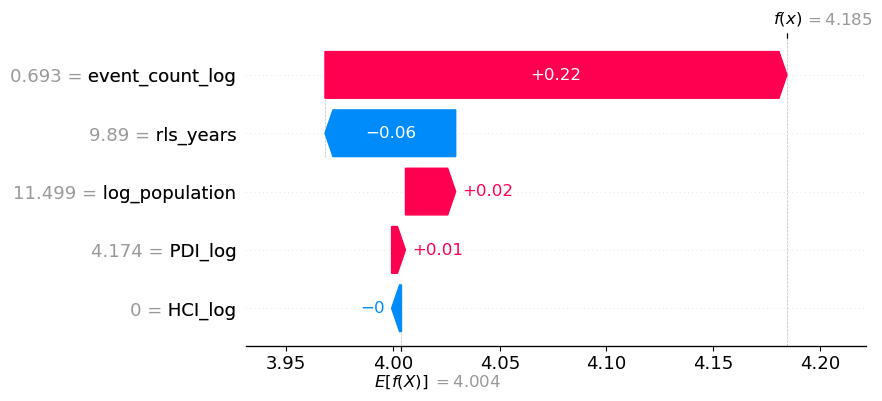

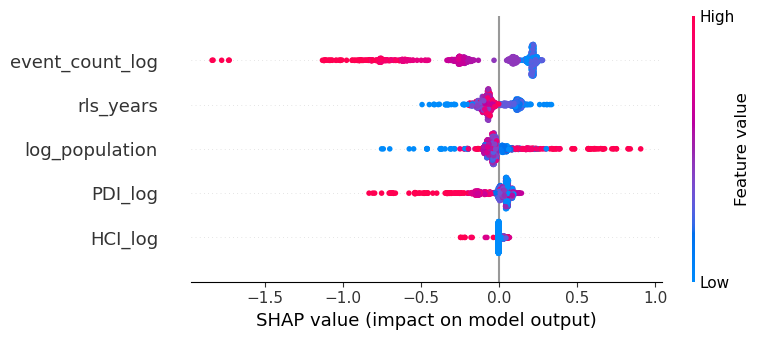

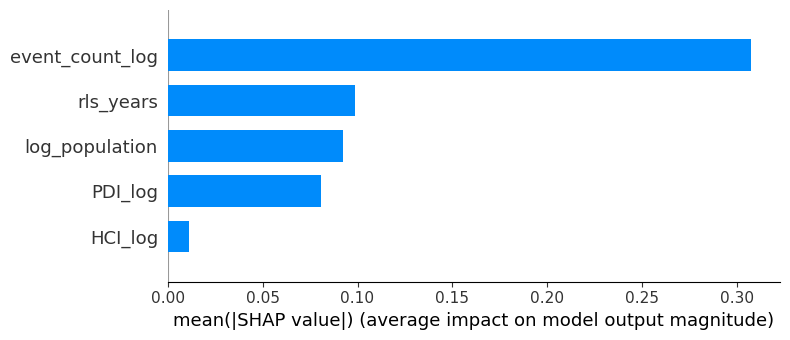


── How to read these SHAP outputs ──
• BASE VALUE (≈ 4.0): the average growth the model predicts before
  any feature is considered. Every prediction starts here.
• WATERFALL: shows how one regency's prediction is built — each
  feature pushes the prediction up (red) or down (blue) from the base.
  Here the pushes are tiny, so the prediction barely leaves the base.
• BEESWARM: each dot is one regency; position = SHAP value (impact on
  prediction), colour = whether the feature value is high or low.
  Points cluster near zero → features rarely move the prediction much.
• BAR: average |SHAP| per feature — the overall importance ranking.
• Together they show the same story as R²≈0: flood features contribute
  little, so predictions stay close to the ~4% baseline for every regency.


In [22]:
# ══════════════════════════════════════════════════════════════════
# SHAP explained: base value + per-feature contributions + plots
# ══════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt

# --- (a) BASE VALUE: the model's starting point before any feature ---
base_value = explainer.expected_value
print("SHAP base value (baseline prediction)")
print("=" * 52)
print(f"  base value (expected_value) = {base_value:.4f}")
print(f"  mean growth in training     = {y_tr.mean():.4f}")
print(f"  \u2192 the base value is the average prediction \u2014 what the")
print(f"    model guesses before any feature moves it.")
print()

# --- (b) DECOMPOSITION: base + sum(SHAP) = prediction, for one regency ---
_i = 0
_pred = best.predict(X_te.iloc[[_i]])[0]
print("How SHAP builds one prediction (first test regency):")
print(f"  base value            = {base_value:+.4f}")
for _f in FEATURES:
    _sv = shap_values[_i][FEATURES.index(_f)]
    print(f"  + {_f:<18} = {_sv:+.4f}")
print(f"  {'':<20}   {'-'*9}")
print(f"  = model prediction    = {base_value + shap_values[_i].sum():+.4f}")
print(f"  (check: best.predict  = {_pred:+.4f})")
print("=" * 52)

# --- (c) WATERFALL: visual of the same decomposition ---
_expl = shap.Explanation(values=shap_values[_i], base_values=base_value,
                         data=X_te.iloc[_i].values, feature_names=FEATURES)
shap.plots.waterfall(_expl, show=True)

# --- (d) BEESWARM: every point's SHAP, colour = feature value ---
shap.summary_plot(shap_values, X_te, feature_names=FEATURES, show=True)

# --- (e) BAR: mean |SHAP| ranking ---
shap.summary_plot(shap_values, X_te, feature_names=FEATURES, plot_type="bar", show=True)

print("\n\u2500\u2500 How to read these SHAP outputs \u2500\u2500")
print("\u2022 BASE VALUE (\u2248 4.0): the average growth the model predicts before")
print("  any feature is considered. Every prediction starts here.")
print("\u2022 WATERFALL: shows how one regency's prediction is built \u2014 each")
print("  feature pushes the prediction up (red) or down (blue) from the base.")
print("  Here the pushes are tiny, so the prediction barely leaves the base.")
print("\u2022 BEESWARM: each dot is one regency; position = SHAP value (impact on")
print("  prediction), colour = whether the feature value is high or low.")
print("  Points cluster near zero \u2192 features rarely move the prediction much.")
print("\u2022 BAR: average |SHAP| per feature \u2014 the overall importance ranking.")
print("\u2022 Together they show the same story as R\u00b2\u22480: flood features contribute")
print("  little, so predictions stay close to the ~4% baseline for every regency.")

## STEP 8 — Convergence with the FE regression (the complement)

This is the core of the complement argument. We refit the FE model on the same
features and place its results next to XGBoost's. The two methods have different
goals — FE estimates causal effects, XGBoost measures predictive signal — so we
compare **conclusions**, not raw accuracy. If both say flooding is weak, the FE
finding is reinforced against the possibility of missed non-linearity.

A subtlety to report honestly: **FE significance ≠ SHAP importance**. FE asks
whether an effect differs from zero; SHAP asks how much a feature is *used* for
prediction. They can highlight different dimensions while still agreeing that the
overall flood contribution is small.

**Bias–variance reading.** In the bias–variance framework, a model's expected
error decomposes into squared bias, variance, and an irreducible component.
The FE regression is a high-bias / low-variance model (it imposes linearity);
XGBoost is a lower-bias / higher-variance model (it can fit non-linear shape).
When a high-bias linear model and a low-bias flexible model **converge on the
same near-zero R²**, the error is dominated by the *irreducible component* —
the part of the outcome that no model can explain from these predictors. This
is the key interpretive point: the weak result is not a symptom of the wrong
model complexity (too much bias, or too much variance), but evidence that
flooding carries little systematic signal about the outcome. The learning
curve supports this — adding data does not raise validation R², which would be
expected if the limitation were variance rather than irreducible error.

In [24]:
# ═════════════════════════════════════════════════════════════
# STEP 8 — Convergence with the FE regression (the complement)
# ═════════════════════════════════════════════════════════════
from linearmodels.panel import PanelOLS

# Refit FE on the same features (entity + time effects)
_pdat = panel.set_index(["bps_kab_code","year"])
_sub  = _pdat[[OUTCOME] + FEATURES].dropna()
_fe   = PanelOLS(_sub[OUTCOME], _sub[FEATURES],
                 entity_effects=True, time_effects=True, drop_absorbed=True).fit()
_wald = _fe.wald_test(formula=" = ".join(FLOOD) + " = 0")
_fe_sig = [f for f in FLOOD if _fe.pvalues[f] < 0.05]

# XGBoost SHAP flood share (reuse shap_values from §5 if present, else recompute)
try:
    _imp = np.abs(shap_values).mean(axis=0)
except NameError:
    import shap
    _imp = np.abs(shap.TreeExplainer(best).shap_values(X_te)).mean(axis=0)
_flood_share = sum(_imp[FEATURES.index(f)] for f in FLOOD) / _imp.sum()
_top_flood = max(FLOOD, key=lambda f: _imp[FEATURES.index(f)])

print("CONVERGENCE TABLE — FE (causal, linear) vs XGBoost (predictive, non-linear)")
print("="*66)
print(f"{'':<26}{'FE':>18}{'XGBoost':>20}")
print("-"*66)
print(f"{'Goal':<26}{'causal effect':>18}{'predictive signal':>20}")
print(f"{'Specification':<26}{'linear':>18}{'non-linear':>20}")
print(f"{'R2':<26}{_fe.rsquared_within:>18.4f}{gs.best_score_:>20.4f}")
print(f"{'  (which R2)':<26}{'within':>18}{'grouped-CV':>20}")
print(f"{'Flood signal':<26}{('only '+_fe_sig[0].replace('_log','') if _fe_sig else 'none')+' sig':>18}{f'{_flood_share:.0%} of SHAP':>20}")
print(f"{'Flood-block Wald p':<26}{_wald.pval:>18.4f}{'—':>20}")
print(f"{'Top flood dim':<26}{(_fe_sig[0].replace('_log','') if _fe_sig else '—'):>18}{_top_flood.replace('_log',''):>20}")
print("="*66)

print("\nCONCLUSION (complement):")
print(f"  • FE within-R2 ({_fe.rsquared_within:.3f}) and XGBoost CV-R2 ({gs.best_score_:.3f})")
print("    are both near zero → non-linearity adds no predictive power.")
print(f"  • FE flags {(_fe_sig[0].replace('_log','') if _fe_sig else 'no')} dimension as significant;")
print(f"    SHAP ranks {_top_flood.replace('_log','')} highest by predictive use.")
print("    These differ because significance (FE) and importance (SHAP) are")
print("    different concepts — but BOTH agree the overall flood contribution")
print("    is small. The non-linear model does not overturn the FE finding.")
print("  → The FE result is REINFORCED: flooding's weak effect on growth is")
print("    genuine, not an artefact of assuming linearity.")

CONVERGENCE TABLE — FE (causal, linear) vs XGBoost (predictive, non-linear)
                                          FE             XGBoost
------------------------------------------------------------------
Goal                           causal effect   predictive signal
Specification                         linear          non-linear
R2                                    0.0092              0.0169
  (which R2)                          within          grouped-CV
Flood signal                    only PDI sig         68% of SHAP
Flood-block Wald p                    0.0068                   —
Top flood dim                            PDI         event_count

CONCLUSION (complement):
  • FE within-R2 (0.009) and XGBoost CV-R2 (0.017)
    are both near zero → non-linearity adds no predictive power.
  • FE flags PDI dimension as significant;
    SHAP ranks event_count highest by predictive use.
    These differ because significance (FE) and importance (SHAP) are
    different concepts — but 

## STEP 9 — Fair like-for-like comparison (linear vs non-linear)

A direct FE-vs-XGBoost RMSE comparison is a **trap**: FE's fitted values depend
on whether the entity/time effects are included, so the numbers are not
comparable. To compare *functional form* fairly, we put a plain **linear model
(OLS, no entity effects)** against XGBoost under **identical conditions** — same
features, same GroupKFold-by-regency CV, same data. This isolates the one
question that matters: does non-linearity buy anything?

In [26]:
# ═════════════════════════════════════════════════════════════
# STEP 9 — Fair like-for-like comparison (linear vs non-linear)
# ═════════════════════════════════════════════════════════════
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, GroupKFold
from sklearn.metrics import make_scorer

_d = panel[["bps_kab_code", OUTCOME] + FEATURES].dropna()
_gkf = GroupKFold(n_splits=5)
_rmse_scorer = "neg_root_mean_squared_error"

def _cv(model):
    r2 = cross_val_score(model, _d[FEATURES], _d[OUTCOME],
                         groups=_d["bps_kab_code"], cv=_gkf, scoring="r2").mean()
    rmse = -cross_val_score(model, _d[FEATURES], _d[OUTCOME],
                            groups=_d["bps_kab_code"], cv=_gkf, scoring=_rmse_scorer).mean()
    return r2, rmse

_lin_r2, _lin_rmse = _cv(LinearRegression())
_xgb_r2, _xgb_rmse = _cv(best)

print("FAIR COMPARISON — same features, same GroupKFold CV, same data")
print("="*58)
print(f"{'Model':<22}{'CV-R2':>12}{'CV-RMSE':>12}")
print("-"*58)
print(f"{'Linear (OLS)':<22}{_lin_r2:>+12.4f}{_lin_rmse:>12.3f}")
print(f"{'XGBoost (non-linear)':<22}{_xgb_r2:>+12.4f}{_xgb_rmse:>12.3f}")
print(f"{'Difference':<22}{_xgb_r2-_lin_r2:>+12.4f}{_xgb_rmse-_lin_rmse:>+12.3f}")
print("="*58)
if abs(_xgb_r2 - _lin_r2) < 0.02:
    print("\n→ Non-linear and linear perform almost identically. Non-linearity")
    print("  buys essentially nothing here: there is no threshold or interaction")
    print("  structure for the tree model to exploit. This is the like-for-like")
    print("  evidence behind the convergence shown in §6.")
else:
    print("\n→ Non-trivial gap — inspect whether non-linearity helps or hurts.")

print("\nNOTE: This is NOT 'FE vs XGBoost'. FE (with entity effects) is the causal")
print("model reported in menu Economic. Here OLS is a linear yardstick matched to")
print("XGBoost's conditions, purely to test whether functional form matters.")
print("\n── Reading the numbers ──")
print("• Linear-OLS and XGBoost have nearly IDENTICAL CV-R² & RMSE.")
print("• Switching from a linear to a non-linear model does NOT improve prediction.")
print("  There is no threshold/interaction structure for the tree model to exploit.")
print("• Like-for-like evidence: functional form is not the reason R² is low —")
print("  the data simply carry little signal about growth.")

FAIR COMPARISON — same features, same GroupKFold CV, same data
Model                        CV-R2     CV-RMSE
----------------------------------------------------------
Linear (OLS)               +0.0045       2.568
XGBoost (non-linear)       +0.0078       2.563
Difference                 +0.0032      -0.004

→ Non-linear and linear perform almost identically. Non-linearity
  buys essentially nothing here: there is no threshold or interaction
  structure for the tree model to exploit. This is the like-for-like
  evidence behind the convergence shown in §6.

NOTE: This is NOT 'FE vs XGBoost'. FE (with entity effects) is the causal
model reported in menu Economic. Here OLS is a linear yardstick matched to
XGBoost's conditions, purely to test whether functional form matters.

── Reading the numbers ──
• Linear-OLS and XGBoost have nearly IDENTICAL CV-R² & RMSE.
• Switching from a linear to a non-linear model does NOT improve prediction.
  There is no threshold/interaction structure for th

## STEP 10 — Robustness — 3-dimension vs 7-variable feature specification

Mirroring the regression robustness check (9a/9b 3-dim vs 9c/9d 7-var), we test
whether **disaggregating** the three flood dimensions back into their seven raw
components improves prediction. If the grouped-CV R² is similar, disaggregation
adds nothing and the parsimonious 3-dimension specification is preferred — the
same logic, and the same conclusion, as in the linear models. This is the
supervised analogue of the k-means dimension-justification in nb5, but judged by
predictive performance rather than clustering metrics.

In [28]:
# ═════════════════════════════════════════════════════════════
# STEP 10 — Robustness — 3-dimension vs 7-variable feature specificati
# ═════════════════════════════════════════════════════════════
from sklearn.model_selection import cross_val_score

# 7-variable features: event + 6 raw components (log1p), from pre_transform
_pre = pd.read_excel(PANEL_PATH, sheet_name="pre_transform")
_comps = ["deaths","missing","injured","house_flooded","house_damaged","fasum_damaged"]
_m = panel.merge(_pre[["bps_kab_code","year"]+_comps], on=["bps_kab_code","year"], how="left")
for _c in _comps:
    _m[f"{_c}_log"] = np.log1p(_m[_c])
VAR7 = ["event_count_log"] + [f"{_c}_log" for _c in _comps]

specs = {
    "3-dimension (event/HCI/PDI)": FLOOD + CONTROLS,
    "7-variable (raw components)": VAR7 + CONTROLS,
}
# use the tuned hyperparameters from the main model for a fair comparison
_bp = {k: v for k, v in gs.best_params_.items()}
print("Feature-spec comparison (grouped-CV R2 on training years, tuned params):\n")
print(f"{'specification':<30}{'n_feat':>7}{'CV R2':>10}{'std':>8}")
print("-"*55)
spec_results = {}
for name, feats in specs.items():
    dd = _m[(_m.year <= TRAIN_END)][["bps_kab_code", OUTCOME]+feats].dropna()
    mdl = xgb.XGBRegressor(random_state=42, objective="reg:squarederror", **_bp)
    sc = cross_val_score(mdl, dd[feats], dd[OUTCOME],
                         groups=dd["bps_kab_code"], cv=GroupKFold(5), scoring="r2")
    spec_results[name] = (sc.mean(), sc.std(), len(feats))
    print(f"{name:<30}{len(feats):>7}{sc.mean():>+10.4f}{sc.std():>8.3f}")

_r3 = spec_results["3-dimension (event/HCI/PDI)"][0]
_r7 = spec_results["7-variable (raw components)"][0]
print(f"\nDifference (7-var minus 3-dim): {_r7-_r3:+.4f}")
if abs(_r7 - _r3) < 0.01:
    print("→ Negligible difference: disaggregation does NOT improve prediction.")
    print("  The parsimonious 3-dimension specification is preferred, consistent")
    print("  with the FE robustness check (9a/9b vs 9c/9d) and the FSI construction.")
else:
    print("→ Non-trivial difference — inspect which specification is better and why.")

Feature-spec comparison (grouped-CV R2 on training years, tuned params):

specification                  n_feat     CV R2     std
-------------------------------------------------------
3-dimension (event/HCI/PDI)         5   +0.0170   0.007
7-variable (raw components)         9   +0.0175   0.009

Difference (7-var minus 3-dim): +0.0004
→ Negligible difference: disaggregation does NOT improve prediction.
  The parsimonious 3-dimension specification is preferred, consistent
  with the FE robustness check (9a/9b vs 9c/9d) and the FSI construction.


## STEP 11 — Summary table — growth

A consolidated table of every metric produced above, for the write-up. No model
file is saved; the notebook is fully reproducible from the data.

In [30]:
# ═════════════════════════════════════════════════════════════
# STEP 11 — Summary table — growth
# ═════════════════════════════════════════════════════════════
summary = {
    "Outcome": OUTCOME,
    "Best CV-R² (tuned)": round(float(gs.best_score_), 4),
    "Test R² (2024–2025)": round(float(r2_te), 4),
    "Naive R²": round(float(r2_naive), 4),
    "Test RMSE": round(float(rmse_te), 3),
    "FE within-R²": round(float(_fe.rsquared_within), 4),
    "FE flood-Wald p": round(float(_wald.pval), 4),
    "FE significant dim": (_fe_sig[0].replace("_log","") if _fe_sig else "none"),
    "XGB top SHAP dim": _top_flood.replace("_log",""),
    "Flood SHAP share": f"{_flood_share:.0%}",
    "Linear CV-R² (fair)": round(float(_lin_r2), 4),
    "XGBoost CV-R² (fair)": round(float(_xgb_r2), 4),
    "3-dim vs 7-var ΔR²": round(float(_r7 - _r3), 4),
}
print("CONSOLIDATED RESULTS — GROWTH")
print("="*46)
for k, v in summary.items():
    print(f"  {k:<26} {v}")
print("="*46)
print("\nOne-line takeaway:")
print("  Flooding is not a meaningful predictor of GRDP growth. FE (causal,")
print("  linear) and XGBoost (predictive, non-linear) converge on a near-zero")
print("  R²; diagnostics confirm this is stable and not a tuning/data artefact.")

CONSOLIDATED RESULTS — GROWTH
  Outcome                    grdp_growth_pct
  Best CV-R² (tuned)         0.0169
  Test R² (2024–2025)        -0.3412
  Naive R²                   -0.1615
  Test RMSE                  1.939
  FE within-R²               0.0092
  FE flood-Wald p            0.0068
  FE significant dim         PDI
  XGB top SHAP dim           event_count
  Flood SHAP share           68%
  Linear CV-R² (fair)        0.0045
  XGBoost CV-R² (fair)       0.0078
  3-dim vs 7-var ΔR²         0.0004

One-line takeaway:
  Flooding is not a meaningful predictor of GRDP growth. FE (causal,
  linear) and XGBoost (predictive, non-linear) converge on a near-zero
  R²; diagnostics confirm this is stable and not a tuning/data artefact.


In [31]:
# ═══════════════════════════════════════════════════════════════════════
# SNIPPET TO ADD IN EACH XGBoost/SHAP NOTEBOOK (growth, poverty, tpt).
# Run AFTER shap_values and X_te exist. It saves the mean|SHAP| per feature
# to a small CSV so a separate script can combine all three into one figure.
#
# Change OUTCOME for each notebook: "growth", "poverty", or "tpt".
# ═══════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd

OUTCOME = "grdp_growth_pct"   # <-- CHANGE per notebook: "growth" / "poverty" / "tpt"

# mean absolute SHAP per feature (the bar-chart quantity)
mean_abs = np.abs(shap_values).mean(axis=0)          # shape: (n_features,)
df_shap = pd.DataFrame({
    "feature": FEATURES,
    "mean_abs_shap": mean_abs,
})
# mark which features are flood dimensions vs structural controls
flood_feats = {"event_count_log", "HCI_log", "PDI_log"}   # adjust to your names
df_shap["group"] = df_shap["feature"].apply(
    lambda f: "flood" if f in flood_feats else "control")
df_shap = df_shap.sort_values("mean_abs_shap", ascending=False)

df_shap.to_csv(f"../data/processed/shap_meanabs_{OUTCOME}.csv", index=False)
print(f"Saved ../data/processed/shap_meanabs_{OUTCOME}.csv")
print(df_shap)

Saved ../data/processed/shap_meanabs_grdp_growth_pct.csv
           feature  mean_abs_shap    group
0  event_count_log       0.307172    flood
4        rls_years       0.098720  control
3   log_population       0.092178  control
2          PDI_log       0.080708    flood
1          HCI_log       0.011316    flood


In [50]:
# ═══════════════════════════════════════════════════════════════════════
# SNIPPET TO ADD IN EACH XGBoost/SHAP NOTEBOOK (growth, poverty, tpt).
# Saves the beeswarm plot as its own standalone PNG, so a separate script
# can stitch the three together into one 3-panel appendix figure.
#
# Run AFTER shap_values and X_te (or sv / X_te for TPT) already exist.
# Change OUTCOME and the variable names per notebook as noted below.
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import shap

OUTCOME = "grdp_growth_pct"   
# --- growth & poverty use: shap_values, FEATURES ---------------------------
plt.figure()
shap.summary_plot(shap_values, X_te, feature_names=FEATURES, show=False)
plt.title({"grdp_growth_pct": "GRDP growth",
           "poverty_pct": "Poverty",
           "tpt_pct": "Unemployment"}[OUTCOME], fontsize=11)
plt.tight_layout()
plt.savefig(f"../figures/shap_beeswarm_{OUTCOME}.png", dpi=200, bbox_inches="tight")
plt.close()
print(f"Saved ../figures/shap_beeswarm_{OUTCOME}.png")

Saved ../figures/shap_beeswarm_grdp_growth_pct.png
